**Seda Kart**

General Research Project

**Generative AI Declaration**

Claude (Anthropic) was used to write and debug code in this notebook and to improve figures. Decisions on cohort design, model selection, and treatment of class imbalance were made by the project team. All code was checked and executed by me before its outputs were used in the report. Full AI use declaration can be found in the report.

# Phase 3: Clustering and Persona Evolution

**Project:** Student Dropout Survival Analysis (Bayes 26D)
**Random seed:** 42 (fixed for every clustering, sampling and jitter call)

## What this notebook does

Phases 1 and 2 asked a supervised question: given what is known about a student at a checkpoint, can it be predicted whether they survive to the next one? This notebook turns to the unsupervised counterpart, where there is no answer to predict and only structure to find. What kinds of students enter the course, and which kinds are still present at each checkpoint?

## The method

- Every student is placed on an engagement against performance plane, using only information available at the first checkpoint.
- Students are grouped into personas twice: once by a median split into quadrants, once by k-means, and the two groupings are compared.
- The persona labels are then held fixed while the mix is tracked from Cohort 1 through Cohort 4 and on to completion.
- Each entry persona is traced to its eventual outcome, connecting the persona story to Phase 2's findings on the early Cohort 1 dropouts and the administrative dropouts of Cohort 4.
- The survival labels are never used as clustering inputs. They enter only afterwards, to trace where each persona ends up.

**Consumes:** `data/processed/cohort_{1..4}.parquet`, Phase 1's outputs. The raw CSV is never read.
**Produces:** a persona assignment for every student and persona-mix tables in `outputs/tables/`, plus figures in `outputs/figures/`.

## 3.0 Imports and global settings

Imports, the fixed seed, and the chart styling used throughout. Each persona keeps the same colour in every figure, so a reader can follow one group across the notebook, and the five exit-depth stages in Section 3.7 use a single-hue ramp rather than four unrelated colours.

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42

# Setting a shared chart styling
INK      = '#222222'   # primary text
INK_2    = '#444444'   # secondary text
MUTED    = '#666666'   # axis tick labels
BASELINE = '#cccccc'   # axis and reference lines

sns.set_theme(style='white', rc={
    'axes.edgecolor':  BASELINE,
    'axes.labelcolor': INK_2,
    'text.color':      INK,
    'xtick.color':     MUTED,
    'ytick.color':     MUTED,
    'legend.frameon':  False,
    'savefig.dpi':     200,
    'savefig.bbox':    'tight',
})

# One fixed colour per persona, identical in every figure. The order is fixed and
# never reshuffled, so a persona keeps its colour across the whole notebook.
PERSONA_ORDER = ['Engaged achiever', 'Detached achiever', 'Engaged struggler', 'Disengaged']
PERSONA_COLOR = {
    'Engaged achiever':  '#0173b2',   # blue
    'Detached achiever': '#de8f05',   # orange
    'Engaged struggler': '#029e73',   # green
    'Disengaged':        '#949494',   # grey
}
# Text colour that stays readable on top of each persona colour
PERSONA_LABEL_INK = {
    'Engaged achiever': 'white', 'Detached achiever': INK,
    'Engaged struggler': 'white', 'Disengaged': INK,
}
# One-hue ordered ramp, light to dark, for the five exit-depth stages in Section 3.7
DEPTH_RAMP = ['#c6dbef', '#9ecae1', '#6baed6', '#4292c6', '#08519c']
DEPTH_LABEL_INK = [INK, INK, INK, 'white', 'white']

print(f'Seed: {SEED}')

Seed: 42


### Paths, constants and a file check

Phase 3 reads only the four amortised-engagement cohort files. The `_noeng` variants exist for the with and without comparison in Phase 2; the engagement axis here is built from the amortised values, and Section 3.2 sets out what that implies.

In [3]:
DATA_DIR  = Path('data/processed')
FIG_DIR   = Path('outputs/figures')
TABLE_DIR = Path('outputs/tables')
for d in [FIG_DIR, TABLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Each cohort's binary target (1 = survives to the next checkpoint)
TARGETS = {
    1: 'survives_phase_1',
    2: 'survives_phase_2',
    3: 'survives_phase_3',
    4: 'survives_to_certificate',
}

# Cohort sizes from Phase 1
EXPECTED_N = {1: 18_724, 2: 17_512, 3: 15_207, 4: 13_632}

for i in range(1, 5):
    path = DATA_DIR / f'cohort_{i}.parquet'
    assert path.exists(), f'Missing Phase 1 output: {path}'
print('All four cohort files present.')

All four cohort files present.


## 3.1 Load the cohorts and rebuild each student's journey

Tracking personas across cohorts requires knowing, for every student in Cohort 1, how far they got. Phase 1 computed each student's lifespan, the number of cohorts they appear in, but never saved it as a column, and the saved files carry a technical wrinkle: each cohort file's row index was reset to 0, 1, 2 and so on when written, so no student ID column links the files.

A reliable link survives, though. Phase 1 built each cohort by filtering the previous one, keeping the surviving rows without reordering them, so Cohort 2's rows are exactly Cohort 1's surviving rows in the same order, and so on down the chain. The next cell verifies this rather than assuming it, comparing the columns that neighbouring cohorts share, value by value, across every row, and stopping the notebook if a single value disagrees. The three amortised engagement columns are excluded from the check, since their values are expected to differ between cohorts as the revealed share grows. The three links are checked on 5, 8 and 10 shared columns across 17,512, 15,207 and 13,632 rows, so an accidental match is not realistically possible.

Once the chain is verified, every student receives a stable ID, their row position in Cohort 1, and their lifespan is read from the survival targets:

| Lifespan | Meaning | Read from |
|---|---|---|
| 1 | left after Test 1 | `survives_phase_1 = 0` |
| 2 | left after Test 2 | survived Cohort 1, `survives_phase_2 = 0` |
| 3 | left after Test 3 | survived Cohort 2, `survives_phase_3 = 0` |
| 4 | present for all four cohorts | survived Cohort 3 |

Lifespan-4 students then split into completers, where `survives_to_certificate = 1`, and administrative dropouts, who finished the whole course but never received the certificate because the final fee went unpaid. Every count is checked against the figures Phase 1 produced, so the notebook fails loudly if anything has drifted.

In [4]:
cohorts = {i: pd.read_parquet(DATA_DIR / f'cohort_{i}.parquet') for i in range(1, 5)}

# Checking expected sizes, and that no cohort contains a missing value
for i, df in cohorts.items():
    assert len(df) == EXPECTED_N[i], f'Cohort {i}: expected {EXPECTED_N[i]:,} rows, got {len(df):,}'
    assert df.isna().sum().sum() == 0, f'Cohort {i} contains missing values - Phase 1 output is corrupt'

# Excluded from the identity check: amortised values legitimately change
# between cohorts (the revealed share is total / lifespan * cohort number)
ENGAGEMENT_COLS = ['forum Q', 'forum A', 'office hour visits']

def verify_chain_link(parent, child, target_col):
    """Prove that `child`'s rows are exactly `parent`'s surviving rows, in order."""
    shared = [c for c in parent.columns
              if c in child.columns and c not in ENGAGEMENT_COLS]
    survivors = parent.loc[parent[target_col] == 1, shared].reset_index(drop=True)
    matches = survivors.astype(float).equals(child[shared].reset_index(drop=True).astype(float))
    assert matches, f'Row-order link broken between cohorts (checked columns: {shared})'
    return len(shared)

for i in range(1, 4):
    n_cols = verify_chain_link(cohorts[i], cohorts[i + 1], TARGETS[i])
    print(f'Cohort {i} -> Cohort {i + 1}: link verified on {n_cols} shared columns, '
          f'all {len(cohorts[i + 1]):,} rows identical')

Cohort 1 -> Cohort 2: link verified on 5 shared columns, all 17,512 rows identical
Cohort 2 -> Cohort 3: link verified on 8 shared columns, all 15,207 rows identical
Cohort 3 -> Cohort 4: link verified on 10 shared columns, all 13,632 rows identical


In [5]:
# ids[j] = Cohort-1 row positions of the students present in cohort j
ids = {1: np.arange(len(cohorts[1]))}
ids[2] = ids[1][cohorts[1][TARGETS[1]].to_numpy() == 1]
ids[3] = ids[2][cohorts[2][TARGETS[2]].to_numpy() == 1]
ids[4] = ids[3][cohorts[3][TARGETS[3]].to_numpy() == 1]
completed_ids = ids[4][cohorts[4][TARGETS[4]].to_numpy() == 1]

n_students = len(cohorts[1])
lifespan = np.ones(n_students, dtype=int)      # everyone participated in Cohort 1
for j in (2, 3, 4):
    lifespan[ids[j]] = j

OUTCOME_ORDER = ['Left after Test 1', 'Left after Test 2', 'Left after Test 3',
                 'Administrative dropout', 'Completed']
outcome = np.empty(n_students, dtype=object)
outcome[lifespan == 1] = 'Left after Test 1'
outcome[lifespan == 2] = 'Left after Test 2'
outcome[lifespan == 3] = 'Left after Test 3'
outcome[ids[4]]        = 'Administrative dropout'
outcome[completed_ids] = 'Completed'

# The master frame this notebook builds up: one row per entrant
students = pd.DataFrame({'lifespan': lifespan, 'outcome': outcome})
students.index.name = 'student_id'

# Checking every count against Phase 1
assert students['lifespan'].value_counts().sort_index().to_dict() == \
    {1: 1_212, 2: 2_305, 3: 1_575, 4: 13_632}, 'Lifespan counts do not match Phase 1'
assert (students['outcome'] == 'Completed').sum() == 11_177
assert (students['outcome'] == 'Administrative dropout').sum() == 2_455
assert (students['outcome'] != 'Completed').sum() == 7_547   # = all dropout = Y rows

print(f'Journey rebuilt for all {n_students:,} students - every count matches Phase 1.\n')
funnel = students['outcome'].value_counts().reindex(OUTCOME_ORDER)
print(pd.DataFrame({'students': funnel,
                    'share of entrants': (funnel / n_students * 100).round(1).astype(str) + '%'
                    }).to_string())

Journey rebuilt for all 18,724 students - every count matches Phase 1.

                        students share of entrants
outcome                                           
Left after Test 1           1212              6.5%
Left after Test 2           2305             12.3%
Left after Test 3           1575              8.4%
Administrative dropout      2455             13.1%
Completed                  11177             59.7%


### The funnel in summary

The 18,724 entrants split exactly as Phase 1 established: 1,212 leave after Test 1, 6.5% of entrants, 2,305 after Test 2 and 1,575 after Test 3. Of the 13,632 who finish the course itself, 2,455 are administrative dropouts, who completed every assessment but never received the certificate, and 11,177, or 59.7%, go on to certify. Everything that follows asks which kinds of students make up each of those numbers.

## 3.2 The two persona axes: engagement and performance at entry

Every student is placed on a plane with two axes:

- **Engagement**: how much visible effort the student puts into the course.
- **Performance**: how well they score when first tested.

**Why entry data only.** The axes use nothing beyond the first checkpoint, so they rest on features every student has regardless of how early they left. Rebuilding the axes for each cohort from that cohort's richer features would measure every cohort on a different yardstick, and a change in the mix could then mean the measurement changed rather than the population. Anchoring on entry features fixes each student's persona the moment Test 1 is done, so any change in the mix can only come from who survives.

**The engagement axis** combines four signals from Cohort 1:

| Component | What it measures |
|---|---|
| mean of `session 1`, `session 2` | percentage of the first two lecture recordings watched |
| `forum Q`, Cohort 1 share | forum questions asked |
| `forum A`, Cohort 1 share | forum answers given |
| `office hour visits`, Cohort 1 share | office-hours attendance |

These sit on different scales, percentages against small counts, so each is standardised to a z-score by subtracting the column mean and dividing by the standard deviation. The axis is the plain average of the four. The next cell compares this average against the first principal component, the single direction capturing the most shared variation, to check whether the simpler construction loses anything.

**The performance axis** is the Test 1 grade, already ordinally encoded by Phase 1 as F=0, D=1, C=2, B=3, A=4. It is standardised for k-means and read as the raw grade for the quadrant view.

**A note on the engagement components.** The three forum and office-hours values are the amortised ones Phase 1 produced: each student's course total divided by their lifespan, then multiplied by the cohort number. In Cohort 1 that leaves a lifespan-1 student showing their whole total and a lifespan-4 student showing a quarter of theirs. The engagement axis is therefore not a pure entry-time measurement; it partly reflects how long a student stayed. Section 2.2 of Phase 2 sets out why the behavioural and arithmetic contributions to that cannot be separated with this data.

The direction matters for what follows. The effect pushes early leavers up the engagement axis, since their whole total appears at once. Any finding that low-engagement students leave early would therefore be working against this effect rather than being produced by it.

In [6]:
c1 = cohorts[1]

eng_components = pd.DataFrame({
    'lecture attendance': (c1['session 1'] + c1['session 2']) / 2,
    'forum questions':    c1['forum Q'],
    'forum answers':      c1['forum A'],
    'office hours':       c1['office hour visits'],
})
z = (eng_components - eng_components.mean()) / eng_components.std(ddof=0)

students['engagement_score'] = z.mean(axis=1).to_numpy()
students['test1_grade']      = c1['test 1'].to_numpy()
students['performance_z']    = ((students['test1_grade'] - students['test1_grade'].mean())
                                / students['test1_grade'].std(ddof=0))

print('How the four engagement components correlate:')
print(eng_components.corr().round(2).to_string())

# Robustness check: does the simple average agree with the first principal component?
pca = PCA(n_components=1, random_state=SEED)
pc1 = pca.fit_transform(z.to_numpy())[:, 0]
agreement = abs(np.corrcoef(students['engagement_score'], pc1)[0, 1])
print(f'\nSimple average vs first principal component: |correlation| = {agreement:.3f} '
      f'(PC1 explains {pca.explained_variance_ratio_[0]:.0%} of component variance)')

axis_corr = np.corrcoef(students['engagement_score'], students['test1_grade'])[0, 1]
print(f'Correlation between the two axes (engagement vs Test 1 grade): {axis_corr:+.2f}')

How the four engagement components correlate:
                    lecture attendance  forum questions  forum answers  office hours
lecture attendance                1.00             0.09           0.17         -0.01
forum questions                   0.09             1.00           0.34          0.31
forum answers                     0.17             0.34           1.00          0.41
office hours                     -0.01             0.31           0.41          1.00

Simple average vs first principal component: |correlation| = 0.970 (PC1 explains 44% of component variance)
Correlation between the two axes (engagement vs Test 1 grade): -0.11


### What the axis construction showed

- The three count-based components correlate moderately with each other, 0.31 to 0.41: students who ask questions also tend to answer them and to visit office hours. Lecture attendance is close to independent of all three, correlating 0.09, 0.17 and −0.01, so the axis blends two different kinds of effort, watching and participating, rather than repeating one signal four times.
- The simple average correlates 0.970 with the first principal component, so the interpretable construction ranks students almost identically to the statistical one. PC1 explains 44% of component variance, however, which confirms the four components are not measuring a single underlying quantity. The axis is an aggregation of distinct behaviours rather than a proxy for one latent trait.
- The two axes correlate at −0.11, so at entry effort and attainment are close to independent with a faint negative tilt. Two near-independent axes are what a two-by-two split needs, and all four quadrants should be populated.

## 3.3 View 1: the two-by-two quadrant personas

The interpretable approach: split each axis at its median and name the four corners. Two practical notes before the code.

The engagement score is continuous, so its median split is clean: exactly half the students, 9,362, sit on each side.

The Test 1 grade has only five possible values, so an exact 50/50 split is impossible. The median grade is a C, and high performance is defined as a grade strictly above the median, meaning a B or an A on Test 1. That is 8,052 students, 43% of entrants, and it is also the natural reading of "high performer".

| Persona | Engagement | Test 1 | Description |
|---|---|---|---|
| Engaged achiever | high | B/A | works hard and scores well |
| Detached achiever | low | B/A | scores well with little visible effort |
| Engaged struggler | high | F/D/C | works hard without yet converting effort into grades |
| Disengaged | low | F/D/C | little effort, weak grades |

In [7]:
ENG_MEDIAN   = students['engagement_score'].median()
GRADE_MEDIAN = students['test1_grade'].median()          # = 2.0, a C

high_eng  = students['engagement_score'] > ENG_MEDIAN
high_perf = students['test1_grade'] > GRADE_MEDIAN       # strictly above C = B or A

students['persona_quadrant'] = np.select(
    [high_eng & high_perf, ~high_eng & high_perf, high_eng & ~high_perf],
    ['Engaged achiever', 'Detached achiever', 'Engaged struggler'],
    default='Disengaged',
)

print(f'Engagement median: {ENG_MEDIAN:+.3f}   (above: {high_eng.sum():,} students)')
print(f'Grade median:      {GRADE_MEDIAN:.0f} (C)     (above, i.e. B/A: {high_perf.sum():,} students)\n')

quad_counts = students['persona_quadrant'].value_counts().reindex(PERSONA_ORDER)
assert quad_counts.sum() == n_students
print(pd.DataFrame({'students': quad_counts,
                    'share': (quad_counts / n_students * 100).round(1).astype(str) + '%'
                    }).to_string())

Engagement median: +0.005   (above: 9,362 students)
Grade median:      2 (C)     (above, i.e. B/A: 8,052 students)

                   students  share
persona_quadrant                  
Engaged achiever       3555  19.0%
Detached achiever      4497  24.0%
Engaged struggler      5807  31.0%
Disengaged             4865  26.0%


### Reading the entry mix

The four personas are all well populated but not equal in size.

Engaged struggler at 31.0% and Disengaged at 26.0% are the two largest groups, followed by Detached achiever at 24.0% and Engaged achiever at 19.0%.

Exactly 25% each was never possible. The engagement axis splits 50/50 by construction, but the grade split is 43/57, so the two achiever personas together account for 43% of entrants regardless of how the engagement axis falls.

Independent axes would therefore give 21.5% and 28.5% in each engagement half. The observed figures sit about 2.5 points either side of that: engaged achievers and disengaged students are slightly rarer than independence predicts, engaged strugglers and detached achievers slightly commoner. That is the −0.11 correlation showing up in the counts, and it is a small effect next to the grade split itself.

## 3.4 The persona plane

One scatter plot: every entrant positioned by engagement on the x axis and Test 1 grade on the y, coloured by persona, with the two median split lines drawn in. Because the grade takes only five values, dots would stack into five invisible lines, so a small random vertical jitter of ±0.18 of a grade step, seeded, spreads them out for display only. The underlying data is untouched.

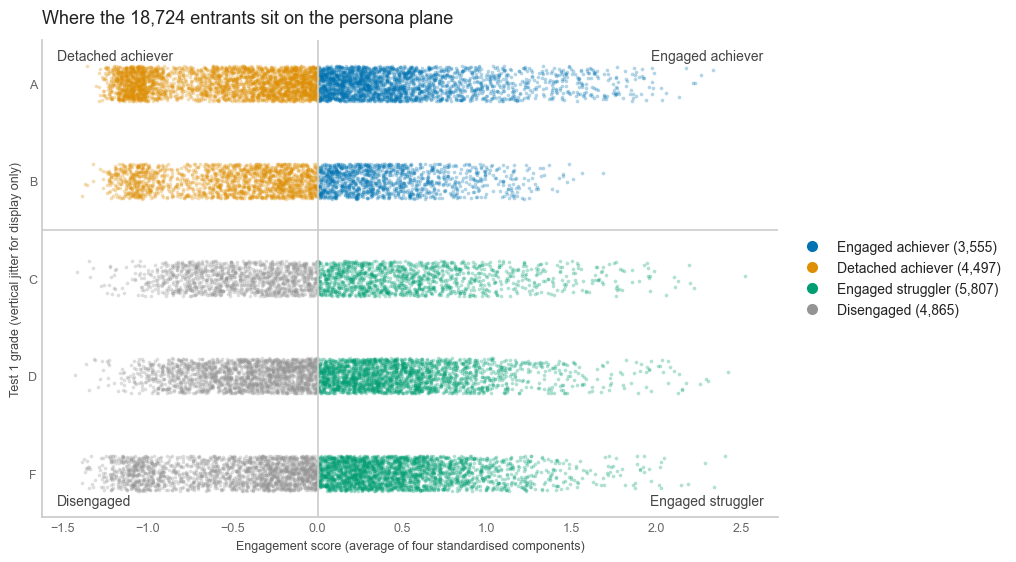

In [8]:
rng = np.random.default_rng(SEED)
y_jitter = students['test1_grade'] + rng.uniform(-0.18, 0.18, n_students)

fig, ax = plt.subplots(figsize=(9.5, 6.2))
for persona in PERSONA_ORDER:
    m = (students['persona_quadrant'] == persona).to_numpy()
    ax.scatter(students['engagement_score'][m], y_jitter[m],
               s=7, alpha=0.30, color=PERSONA_COLOR[persona],
               linewidths=0, rasterized=True)

ax.axvline(ENG_MEDIAN, color=BASELINE, lw=1.2, zorder=3)
ax.axhline(2.5, color=BASELINE, lw=1.2, zorder=3)   # boundary between grade C and B

# Direct quadrant labels: position carries identity, the legend carries the counts
for label, x, y, ha in [('Detached achiever', 0.02, 0.98, 'left'),
                        ('Engaged achiever',  0.98, 0.98, 'right'),
                        ('Disengaged',        0.02, 0.02, 'left'),
                        ('Engaged struggler', 0.98, 0.02, 'right')]:
    ax.text(x, y, label, transform=ax.transAxes, ha=ha,
            va='top' if y > 0.5 else 'bottom', fontsize=10,
            color=INK_2)

handles = [Line2D([], [], marker='o', linestyle='', markersize=8,
                  markerfacecolor=PERSONA_COLOR[p], markeredgecolor='none',
                  label=f'{p} ({quad_counts[p]:,})') for p in PERSONA_ORDER]
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=10)

ax.set_yticks(range(5))
ax.set_yticklabels(['F', 'D', 'C', 'B', 'A'])
ax.set_ylim(-0.45, 4.45)
ax.set_xlabel('Engagement score (average of four standardised components)', fontsize=9)
ax.set_ylabel('Test 1 grade (vertical jitter for display only)', fontsize=9)
ax.set_title('Where the 18,724 entrants sit on the persona plane',
             fontsize=13, pad=12, loc='left')

ax.grid(False)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0, labelsize=9)

fig.savefig(FIG_DIR / 'persona_plane_quadrants.png')
plt.show()

### What the plot shows

The five grade bands are clearly visible as horizontal stripes, and within each band students spread smoothly along the engagement axis. There are no separated islands. The population is a continuous cloud, and the quadrant borders are conventions drawn through it rather than gaps discovered in it.

That observation bears on the next section. A cloud with no natural gaps offers k-means nothing obvious to separate, so whatever it returns will be a partition of continuous data rather than the discovery of distinct groups. Section 3.5 tests how far that holds.

## 3.5 View 2: data-driven personas with k-means

The two-by-two view of Section 3.3 rests on two choices: which axes to use, and where to cut them. That leaves open whether the four types are in the data or drawn onto it. K-means addresses this directly, since it groups students on their numerical positions alone, with no knowledge of what the axes mean. If it recovers the same four types unaided, the quadrants stop being a convention and become a finding.

The number of clusters has to be supplied, so two diagnostics guide the choice. The elbow method plots inertia against k and looks for the point where additional clusters stop buying much extra tightness. The silhouette score measures how much closer each student sits to their own cluster than to the nearest rival, averaged across the population; it is computed here on a seeded 10,000-student sample, since a full pairwise calculation over 18,724 students costs minutes without changing the result.

Two implementation details matter.

Both axes are re-standardised before clustering, so each contributes equally to the distance calculation. The averaged engagement score has a smaller spread than the single z-scored performance value, and since k-means reasons purely in distances, the wider axis would otherwise dominate every assignment.

The model is fitted once on Cohort 1 and then held fixed. Centroids are learned from the full entry population and never refitted, so a student keeps the same label at every stage. This is the anchoring rule the quadrant view uses, for the same reason: if clusters were re-learned at each stage, a change in the mix could mean the students changed or the definitions moved, and the two would be indistinguishable. Because every later cohort is a subset of Cohort 1, no extra code is needed; each surviving student's fixed label is looked up at each later stage.

     inertia  silhouette inertia drop
k                                    
2  21678.715       0.413            -
3  14912.066       0.390          31%
4  10175.459       0.398          32%
5   8267.102       0.403          19%
6   6725.638       0.385          19%
7   5707.449       0.391          15%
8   4972.015       0.416          13%


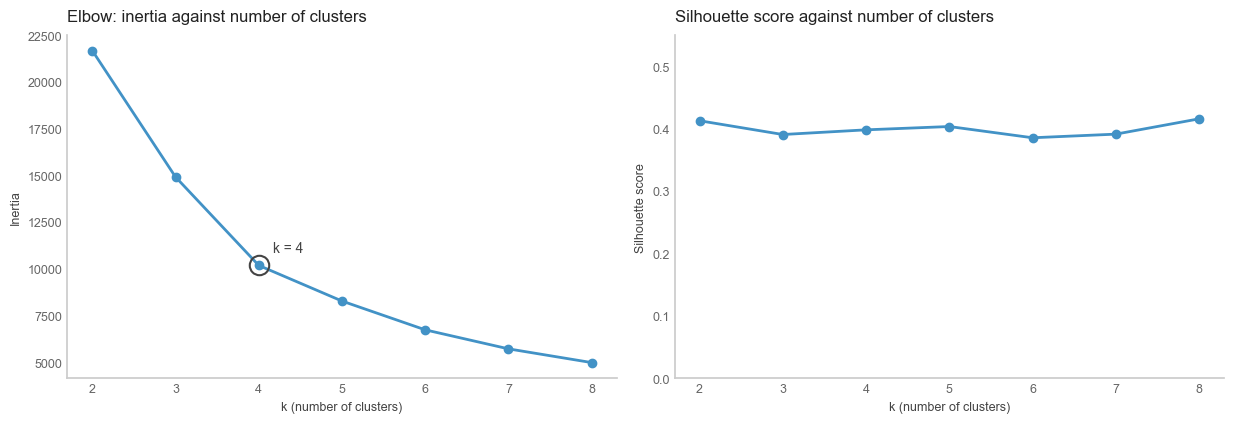

In [9]:
scaler_km = StandardScaler()
X_km = scaler_km.fit_transform(students[['engagement_score', 'performance_z']])

K_RANGE = range(2, 9)
diagnostics = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_km)
    sil = silhouette_score(X_km, km.labels_, sample_size=10_000, random_state=SEED)
    diagnostics.append({'k': k, 'inertia': km.inertia_, 'silhouette': sil})

diag = pd.DataFrame(diagnostics).set_index('k')
diag['inertia drop'] = (-diag['inertia'].pct_change() * 100).map(
    lambda v: f'{v:.0f}%' if pd.notna(v) else '-')
print(diag.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, col, title, ylab in [
        (axes[0], 'inertia',    'Elbow: inertia against number of clusters', 'Inertia'),
        (axes[1], 'silhouette', 'Silhouette score against number of clusters', 'Silhouette score')]:
    ax.plot(diag.index, diag[col], color='#4292c6', lw=2, marker='o', markersize=6)
    if col == 'inertia':
        ax.plot(4, diag.loc[4, col], marker='o', markersize=14,
                markerfacecolor='none', markeredgecolor=INK_2, markeredgewidth=1.5)
        ax.annotate('k = 4', (4, diag.loc[4, col]), textcoords='offset points',
                    xytext=(10, 10), fontsize=10, color=INK_2)
    ax.set_xlabel('k (number of clusters)', fontsize=9)
    ax.set_ylabel(ylab, fontsize=9)
    ax.set_title(title, fontsize=12, pad=10, loc='left')
    ax.grid(False)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0, labelsize=9)

axes[1].set_ylim(0, 0.55)

fig.tight_layout()
fig.savefig(FIG_DIR / 'kmeans_k_selection.png')
plt.show()

### Choosing k

The two diagnostics point in different directions, and reading them together settles both which k to use and how much weight the clusters can bear.

The elbow points to k = 4. Moving from three clusters to four reduces inertia by 4,737; moving from four to five reduces it by 1,908. That 60% collapse in marginal gain is the sharpest break anywhere in the range, and every other step-to-step ratio sits between 0.66 and 0.81. The fourth cluster still buys a substantially tighter description of the data, while the fifth mostly subdivides groups that were already coherent.

The silhouette is nearly flat, between 0.385 and 0.416 across k = 2 to 8, with k = 8 marginally highest at 0.416 and k = 4 fourth at 0.398. No value stands out, and that is itself informative: it confirms what the scatter plot in Section 3.4 showed, a continuous cloud with soft structure rather than well-separated islands. Any small k is therefore a lens rather than a discovery of the true number of student types. The level of the score, around 0.4 rather than near zero, indicates the lens is focusing on real structure even so.

k = 4 is used from here. The elbow supports it on the evidence, and it also allows the data-driven view to be compared cell for cell against the four quadrant personas.

In [10]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_km)
raw_labels = km4.labels_

# Centroids back in interpretable units
centroids = pd.DataFrame(scaler_km.inverse_transform(km4.cluster_centers_),
                         columns=['engagement_score', 'performance_z'])
g_mean = students['test1_grade'].mean()
g_std  = students['test1_grade'].std(ddof=0)
centroids['mean Test 1 grade'] = centroids['performance_z'] * g_std + g_mean
centroids['students'] = pd.Series(raw_labels).value_counts().sort_index()

# Name each cluster by the quadrant its centroid lands in, and give it the
# colour of its quadrant twin so the two views are visually comparable.
QUAD_TO_PERSONA = {(True, True):  'Engaged achiever',  (False, True):  'Detached achiever',
                   (True, False): 'Engaged struggler', (False, False): 'Disengaged'}
km_name, twin_of = {}, {}
for cid in range(4):
    e = centroids.loc[cid, 'engagement_score'] > ENG_MEDIAN
    g = centroids.loc[cid, 'mean Test 1 grade'] > 2.5
    name = f"{'High' if e else 'Low'} eng / {'high' if g else 'low'} grades"
    km_name[cid] = name
    twin_of[name] = QUAD_TO_PERSONA[(e, g)]
assert len(set(km_name.values())) == 4, 'Two centroids landed in the same quadrant - naming needs review'

KM_ORDER     = sorted(twin_of, key=lambda nm: PERSONA_ORDER.index(twin_of[nm]))
KM_COLOR     = {nm: PERSONA_COLOR[twin_of[nm]] for nm in KM_ORDER}
KM_LABEL_INK = {nm: PERSONA_LABEL_INK[twin_of[nm]] for nm in KM_ORDER}
students['persona_kmeans'] = pd.Series(raw_labels).map(km_name).to_numpy()

centroids.index = [km_name[c] for c in centroids.index]
print('The four k-means centroids, in real units:\n')
print(centroids[['engagement_score', 'mean Test 1 grade', 'students']].round(2).to_string())

ari = adjusted_rand_score(students['persona_quadrant'], raw_labels)
print(f'\nAgreement between the two views (adjusted Rand index): {ari:.2f}')
print('\nWho went where (quadrant persona vs k-means cluster):')
print(pd.crosstab(students['persona_quadrant'], students['persona_kmeans'])
        .reindex(index=PERSONA_ORDER, columns=KM_ORDER).to_string())

The four k-means centroids, in real units:

                        engagement_score  mean Test 1 grade  students
Low eng / low grades               -0.41               0.85      5328
High eng / high grades              0.38               3.66      4425
High eng / low grades               0.58               0.80      5266
Low eng / high grades              -0.68               3.59      3705

Agreement between the two views (adjusted Rand index): 0.82

Who went where (quadrant persona vs k-means cluster):
persona_kmeans     High eng / high grades  Low eng / high grades  High eng / low grades  Low eng / low grades
persona_quadrant                                                                                             
Engaged achiever                     3555                      0                      0                     0
Detached achiever                     870                   3627                      0                     0
Engaged struggler                       0         

### The two views agree

K-means places its four centroids one in each quadrant of the plane, so the four types the medians define are also where the distances between students fall. The centroids sit at engagement −0.41 and −0.68 on the low side and 0.38 and 0.58 on the high, with mean Test 1 grades of 0.85 and 0.80 against 3.66 and 3.59.

The adjusted Rand index measures similarity between two groupings, where 0 is no better than shuffling labels and 1 is identical. It comes out at 0.82. The disagreements sit at the borders, since k-means draws slanted boundaries through the cloud while the medians draw right-angled ones. 870 Detached achievers with borderline engagement move into the high-engagement, high-grade cluster, 541 Engaged strugglers move into the low-engagement, low-grade one, and 78 Disengaged students cross the grade line into the low-engagement, high-grade cluster. Every one of those 1,489 students crosses exactly one boundary. No student is placed in the diagonally opposite quadrant, so the two views never disagree about both axes at once.

The agreement is worth reading carefully rather than as independent confirmation. Both views use the same two axes, and the clusters are named here by testing each centroid against the same medians, so the two are not methodologically independent. What the result does establish is that the median cuts fall close to where the data's own structure lies, which would not have been guaranteed.

Results are reported for both views from here, with the quadrant names as the headline and k-means alongside as a check that the pattern survives a change of grouping method.

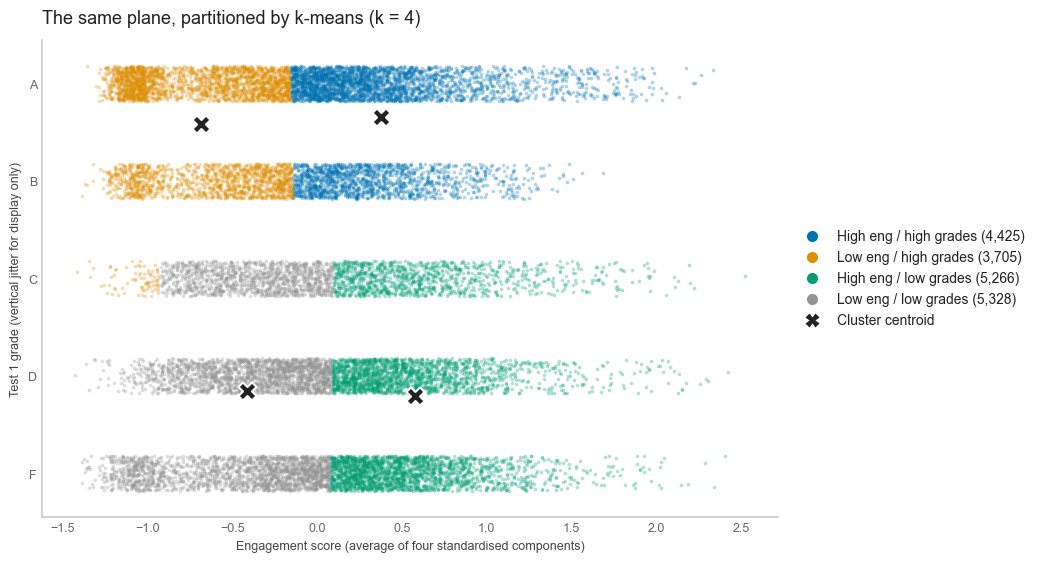

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))
for name in KM_ORDER:
    m = (students['persona_kmeans'] == name).to_numpy()
    ax.scatter(students['engagement_score'][m], y_jitter[m],
               s=7, alpha=0.30, color=KM_COLOR[name], linewidths=0, rasterized=True)

ax.scatter(centroids['engagement_score'], centroids['mean Test 1 grade'],
           marker='X', s=170, color=INK, edgecolor='white', linewidth=1.5, zorder=5)

handles = [Line2D([], [], marker='o', linestyle='', markersize=8,
                  markerfacecolor=KM_COLOR[nm], markeredgecolor='none',
                  label=f'{nm} ({centroids.loc[nm, "students"]:,.0f})') for nm in KM_ORDER]
handles.append(Line2D([], [], marker='X', linestyle='', markersize=10,
                      markerfacecolor=INK, markeredgecolor='none', label='Cluster centroid'))
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=10)

ax.set_yticks(range(5))
ax.set_yticklabels(['F', 'D', 'C', 'B', 'A'])
ax.set_ylim(-0.45, 4.45)
ax.set_xlabel('Engagement score (average of four standardised components)', fontsize=9)
ax.set_ylabel('Test 1 grade (vertical jitter for display only)', fontsize=9)
ax.set_title('The same plane, partitioned by k-means (k = 4)',
             fontsize=13, pad=12, loc='left')

ax.grid(False)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0, labelsize=9)

fig.savefig(FIG_DIR / 'persona_plane_kmeans.png')
plt.show()

## 3.6 How the persona mix evolves

Everything is now in place for the question the notebook has been building towards. The persona labels are frozen: assigned once at entry from entry features alone, so a Disengaged entrant remains a Disengaged entrant however far they get. At each stage the students still present are counted by persona, which turns dropout into a question about composition. As students leave, does the surviving population change in kind or only in size?

| Stage | Who is present | n |
|---|---|---|
| Cohort 1 | everyone | 18,724 |
| Cohort 2 | survived Test 1 | 17,512 |
| Cohort 3 | survived Test 2 | 15,207 |
| Cohort 4 | survived Test 3 | 13,632 |
| Completed | earned the certificate | 11,177 |

The fifth stage extends the four-cohort structure by one step, and it is this notebook's window onto Phase 2's Cohort 4 problem. Phase 2 found administrative dropout hard to predict from behaviour, catching 266 of 491 in the test split. If those students are behaviourally indistinguishable from certifiers, the group removed between Cohort 4 and Completed should be close to a random slice of the cohort and the persona mix should barely move across that step. If the mix shifts noticeably, some behavioural signature of non-payment exists after all.

The prediction under test is that the personas start roughly even and narrow towards the more committed types as the course proceeds. Whether that holds, and whether it holds evenly across all four personas, is what the next cells measure.

In [20]:
STAGES = {'Cohort 1': ids[1], 'Cohort 2': ids[2], 'Cohort 3': ids[3],
          'Cohort 4': ids[4], 'Completed': completed_ids}
STAGE_N = {stage: len(idx) for stage, idx in STAGES.items()}

def persona_mix(col, order):
    """Share (%) of each persona among the students present at each stage."""
    return pd.DataFrame({stage: students[col].iloc[idx].value_counts(normalize=True)
                                 .reindex(order) * 100
                         for stage, idx in STAGES.items()})

mix_quad = persona_mix('persona_quadrant', PERSONA_ORDER)
mix_km   = persona_mix('persona_kmeans', KM_ORDER)

for mix, path in [(mix_quad, 'persona_mix_quadrant.csv'), (mix_km, 'persona_mix_kmeans.csv')]:
    mix.round(2).to_csv(TABLE_DIR / path)

def show_mix(mix, title):
    out = mix.round(1)
    out['change (percentage points)'] = (out['Completed'] - out['Cohort 1']).round(1).map('{:+.1f}'.format)
    print(f'{title} - share of each stage (%)\n')
    print(out.to_string())
    print()

show_mix(mix_quad, 'Quadrant personas')
show_mix(mix_km,   'k-means personas (k = 4)')

Quadrant personas - share of each stage (%)

                   Cohort 1  Cohort 2  Cohort 3  Cohort 4  Completed change (percentage points)
persona_quadrant                                                                               
Engaged achiever       19.0      20.2      20.5      22.3       23.1                       +4.1
Detached achiever      24.0      24.7      25.3      22.8       20.9                       -3.1
Engaged struggler      31.0      32.8      33.8      37.2       40.0                       +9.0
Disengaged             26.0      22.2      20.5      17.7       16.0                      -10.0

k-means personas (k = 4) - share of each stage (%)

                        Cohort 1  Cohort 2  Cohort 3  Cohort 4  Completed change (percentage points)
persona_kmeans                                                                                      
High eng / high grades      23.6      25.1      25.8      27.4       28.2                       +4.6
Low eng / high grades  

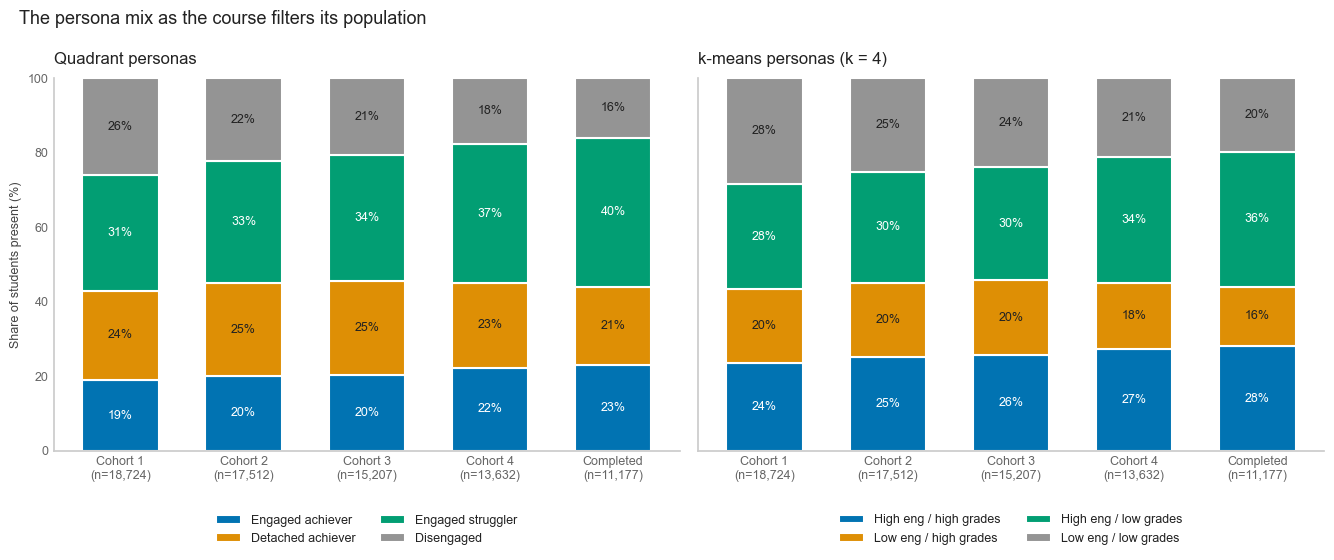

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.8), sharey=True)
panels = [(axes[0], mix_quad, PERSONA_ORDER, PERSONA_COLOR, PERSONA_LABEL_INK, 'Quadrant personas'),
          (axes[1], mix_km,   KM_ORDER,     KM_COLOR,      KM_LABEL_INK,      'k-means personas (k = 4)')]

x = np.arange(len(STAGES))
for ax, mix, order, colors, label_ink, title in panels:
    bottoms = np.zeros(len(STAGES))
    for p in order:
        vals = mix.loc[p].to_numpy()
        ax.bar(x, vals, 0.62, bottom=bottoms, color=colors[p],
               edgecolor='white', linewidth=1.5, label=p)
        for xi, (v, b) in enumerate(zip(vals, bottoms)):
            if v >= 6:                                    # label only segments that fit
                ax.text(xi, b + v / 2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=9, color=label_ink[p])
        bottoms += vals
    ax.set_xticks(x)
    ax.set_xticklabels([f'{s}\n(n={STAGE_N[s]:,})' for s in STAGES], fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_title(title, fontsize=12, pad=10, loc='left')
    ax.grid(False)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0, labelsize=9)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncols=2, fontsize=9)

axes[0].set_ylabel('Share of students present (%)', fontsize=9)
fig.suptitle('The persona mix as the course filters its population',
             fontsize=13, x=0.02, ha='left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'persona_evolution.png')
plt.show()

### Trajectory view

The stacked bars answer what the mix is at each stage, but they make it hard to see how one persona's share moves across stages, because every band except the bottom sits on a baseline that shifts from bar to bar. The line panel below gives each persona its own trajectory, which the eye can follow directly. It plots the same figures from `mix_quad` and `mix_km`, with the same fixed colours, so nothing new is computed.
The y-axis is truncated to the range the shares actually occupy, so the vertical scale exaggerates movement relative to the stacked bars. The bars above give the shares against a full zero-to-100 scale.

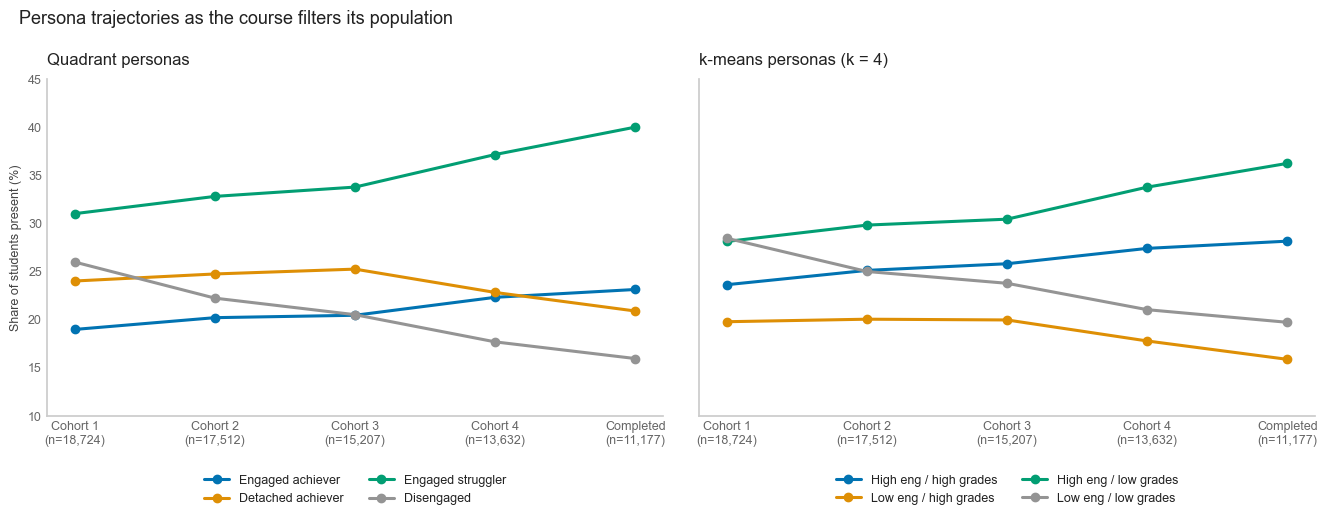

In [14]:
# One line per persona: reads a single persona's path across the funnel more
# clearly than the stacked bars above. Same figures, same fixed persona colours.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharey=True)
panels = [(axes[0], mix_quad, PERSONA_ORDER, PERSONA_COLOR, 'Quadrant personas'),
          (axes[1], mix_km,   KM_ORDER,      KM_COLOR,      'k-means personas (k = 4)')]

x = np.arange(len(STAGES))
for ax, mix, order, colors, title in panels:
    for p in order:
        ax.plot(x, mix.loc[p].to_numpy(), marker='o', markersize=6,
                linewidth=2.2, color=colors[p], label=p)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{s}\n(n={STAGE_N[s]:,})' for s in STAGES], fontsize=9)
    ax.set_ylim(10, 45)
    ax.set_title(title, fontsize=12, pad=10, loc='left')
    ax.grid(False)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0, labelsize=9)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncols=2, fontsize=9)

axes[0].set_ylabel('Share of students present (%)', fontsize=9)
fig.suptitle('Persona trajectories as the course filters its population',
             fontsize=13, x=0.02, ha='left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'persona_evolution_trajectories.png')
plt.show()

### The story in the numbers

The expected narrowing holds, with one refinement that changes what "committed" turns out to mean.

1. The Disengaged persona shrinks at every stage, falling 26.0% to 22.2% to 20.5% to 17.7% to 16.0%. The steepest single drop, 3.8 points, comes at the first checkpoint. That is the early dropout Phase 2's Cohort 1 model identified so easily, and Section 3.7 shows 80% of the 1,212 students who left after Test 1 are Disengaged entrants.

2. The committed personas grow, but committed means engaged rather than high-scoring. The two high-engagement personas together rise from 50.0% of entrants to 63.1% of completers, and the largest single gainer is the Engaged struggler, up from 31.0% to 40.0%, a 9.0-point rise well ahead of the Engaged achiever's 19.0% to 23.1%. Survival is selecting on effort rather than on the first test result.

3. The Detached achiever is the case that forces the refinement. Its share holds through Cohort 3, rising from 24.0% to 25.3%, then falls to 20.9% of completers. Good entry grades carry these students past the early checkpoints, but the missing engagement tells later: Section 3.7 shows 16.2% of them leave after Test 3, against 1.9% of Engaged achievers and 1.2% of Engaged strugglers. On this evidence effort at entry predicts staying and early test scores do not.

4. The step from Cohort 4 to Completed barely moves the mix. No persona shifts by more than 2.8 points, even though the step removes 2,455 students, 18.0% of the cohort. That answers the question Section 3.6 posed: administrative dropout is close to persona-blind, which is the unsupervised counterpart of Phase 2's finding that Cohort 4 resists prediction, at a test F1 of 0.634 against 0.976, 0.977 and 0.989 elsewhere. The small drift that does exist points the same way as Section 3.7's table, where the Detached achiever is modestly over-represented among non-payers at 17.3% against 10.2% to 12.9% for the others, consistent with Phase 2's finding that a subset of non-payers is visible in behaviour while the rest is not.

5. The k-means panel tells the same story with softer borders. Its low-engagement, low-grade cluster falls from 28.5% to 19.7% while both high-engagement clusters grow. The finding therefore does not depend on where exactly the quadrant lines were drawn: redraw them by a different method and the same evolution appears.

## 3.7 Where does each entry persona end up?

The mix tables of Section 3.6 ask who is present at each stage, which is the course's point of view. This section takes the student's: for each entry persona, how deep into the course do its members get? The table is row-normalised, so each persona's row sums to 100% across the five outcomes and reads as the full distribution of fates for that kind of student. The chart uses a single blue ramp, light for leaving early through to dark for completing, so depth is encoded by darkness and a persona's overall survival can be judged from how dark its bar is.

In [15]:
depth = (pd.crosstab(students['persona_quadrant'], students['outcome'], normalize='index')
           .reindex(index=PERSONA_ORDER, columns=OUTCOME_ORDER) * 100)

persona_summary = pd.DataFrame({
    'students':                quad_counts,
    'mean lifespan (cohorts)': students.groupby('persona_quadrant')['lifespan']
                                       .mean().reindex(PERSONA_ORDER).round(2),
    'completion rate (%)':     depth['Completed'].round(1),
})

print('Outcome by entry persona (% of that persona)\n')
print(depth.round(1).to_string())
print('\n')
print(persona_summary.to_string())

depth.round(2).to_csv(TABLE_DIR / 'survival_depth_by_persona.csv')

# The early-dropout pattern, quantified
t1_leavers = students[students['outcome'] == 'Left after Test 1']
dis_share = (t1_leavers['persona_quadrant'] == 'Disengaged').mean()
print(f'\nOf the {len(t1_leavers):,} students who left after Test 1, '
      f'{dis_share:.0%} are Disengaged.')

Outcome by entry persona (% of that persona)

outcome            Left after Test 1  Left after Test 2  Left after Test 3  Administrative dropout  Completed
persona_quadrant                                                                                             
Engaged achiever                 0.5               12.0                1.9                    12.9       72.7
Detached achiever                3.6               11.0               16.2                    17.3       51.9
Engaged struggler                1.1               10.5                1.2                    10.2       77.0
Disengaged                      20.0               15.9               14.6                    12.9       36.7


                   students  mean lifespan (cohorts)  completion rate (%)
persona_quadrant                                                         
Engaged achiever       3555                     3.73                 72.7
Detached achiever      4497                     3.51                 5

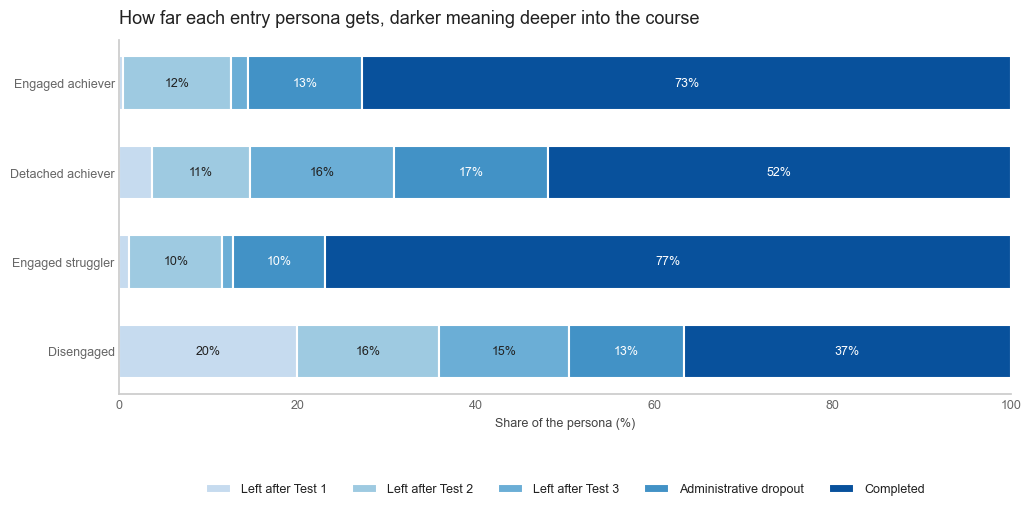

In [22]:
fig, ax = plt.subplots(figsize=(11.5, 4.6))
y = np.arange(len(PERSONA_ORDER))
lefts = np.zeros(len(PERSONA_ORDER))
for stage, color, ink in zip(OUTCOME_ORDER, DEPTH_RAMP, DEPTH_LABEL_INK):
    vals = depth[stage].to_numpy()
    ax.barh(y, vals, 0.6, left=lefts, color=color,
            edgecolor='white', linewidth=1.5, label=stage)
    for yi, (v, l) in enumerate(zip(vals, lefts)):
        if v >= 5:                                        # label only segments that fit
            ax.text(l + v / 2, yi, f'{v:.0f}%', ha='center', va='center',
                    fontsize=9, color=ink)
    lefts += vals

ax.set_yticks(y)
ax.set_yticklabels(PERSONA_ORDER)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Share of the persona (%)', fontsize=9)
ax.set_title('How far each entry persona gets, darker meaning deeper into the course',
             fontsize=13, pad=12, loc='left')

ax.grid(False)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0, labelsize=9)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncols=5, fontsize=9)

fig.savefig(FIG_DIR / 'survival_depth_by_persona.png')
plt.show()

### Heatmap variant of the depth table

A compact alternative to the horizontal bars: the same `depth` table drawn as a heatmap. The bars tell the clearer story for the body of the report, since reading a stacked bar left to right mimics a student moving through the course, but the heatmap packs every persona and outcome into a small footprint and suits a tighter space. Darker means a larger share of that persona ended in that outcome.

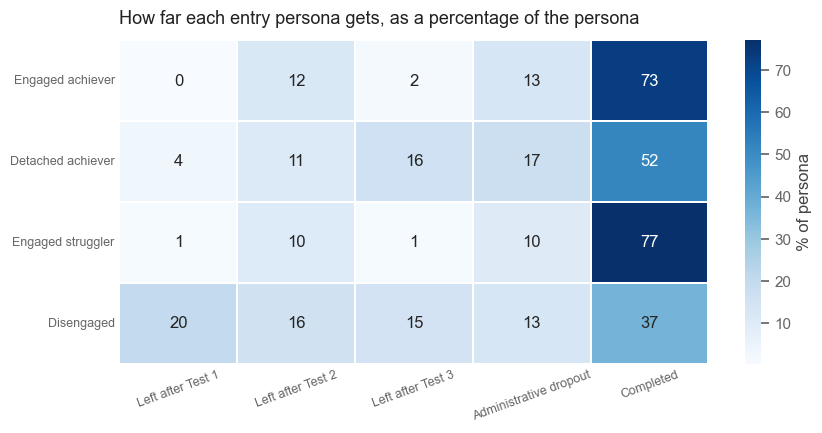

In [17]:
# Compact heatmap of the same survival-depth table, a space-efficient alternative
# to the horizontal bars above, intended for the report appendix.
fig, ax = plt.subplots(figsize=(9.5, 4.2))
sns.heatmap(depth.reindex(index=PERSONA_ORDER, columns=OUTCOME_ORDER),
            annot=True, fmt='.0f', cmap='Blues',
            linewidths=1.2, linecolor='white',
            cbar_kws={'label': '% of persona'}, ax=ax)
ax.set_title('How far each entry persona gets, as a percentage of the persona',
             fontsize=13, pad=12, loc='left')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0, length=0, labelsize=9)
ax.tick_params(axis='x', rotation=20, length=0, labelsize=9)

fig.savefig(FIG_DIR / 'survival_depth_heatmap.png')
plt.show()

### Reading the depth table

Disengaged is the at-risk persona, and by a wide margin. Only 36.7% complete, and 20.0% are gone at the first checkpoint against 0.5% of Engaged achievers. The concentration is starker by head count: 80% of the 1,212 students who left after Test 1 come from this one persona. That is the early-dropout pattern quantified, and it explains why Phase 2's Cohort 1 model reached F1 0.976. Prediction is easy when the students who leave first are overwhelmingly of one clearly marked kind.

Engaged strugglers finish more often than anyone, at 77.0%, ahead of Engaged achievers at 72.7%. That ordering is the notebook's most counter-intuitive result: among students who put in real effort, a weak first grade is no disadvantage. And weak grades with effort beat strong grades without it — the Detached achievers, on good entry grades but little engagement, complete at just 51.9%.

Detached achievers are the quiet risk, with 48.1% never earning the certificate. What makes them quiet is when they leave. Their exits cluster late: 16.2% leave after Test 3, against 1.9% of Engaged achievers and 1.2% of Engaged strugglers, and they carry the highest administrative-dropout share at 17.3%. The pattern reads as entry grades carrying them through the tests while the missing engagement tells at the end, both as late quitting and as non-payment.

Leaving after Test 2 is the least persona-driven exit, varying only from 10.5% to 15.9% across the four personas. Entry-time behaviour says least about the mid-course checkpoint.

### Who makes up each exit?

The depth table above reads across each persona's row: given a kind of student, where do they end up? This view turns the question around and reads down each outcome's column: given an exit point, which personas are leaving there? The two are different questions with different denominators. The depth table shows 20% of Disengaged students leave after Test 1; this chart shows that those Disengaged students are 80% of everyone who leaves after Test 1. Each bar is one outcome, normalised to 100% and split by entry persona.

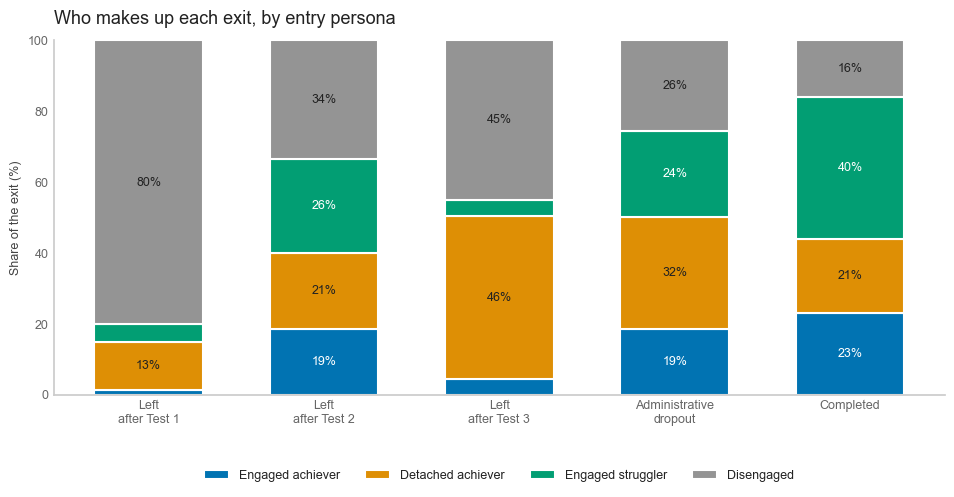

In [18]:
# Column-normalised counterpart of `depth`: each outcome split by persona.
# Answers "who are the leavers at each exit?" where `depth` answers
# "where does each persona go?". Same crosstab, normalised down columns.
composition = (pd.crosstab(students['persona_quadrant'], students['outcome'],
                           normalize='columns')
                 .reindex(index=PERSONA_ORDER, columns=OUTCOME_ORDER) * 100)

fig, ax = plt.subplots(figsize=(11.5, 4.6))
x = np.arange(len(OUTCOME_ORDER))
bottoms = np.zeros(len(OUTCOME_ORDER))
for persona in PERSONA_ORDER:
    vals = composition.loc[persona].to_numpy()
    ax.bar(x, vals, 0.62, bottom=bottoms, color=PERSONA_COLOR[persona],
           edgecolor='white', linewidth=1.5, label=persona)
    for xi, (v, b) in enumerate(zip(vals, bottoms)):
        if v >= 6:                                    # label only segments that fit
            ax.text(xi, b + v / 2, f'{v:.0f}%', ha='center', va='center',
                    fontsize=9, color=PERSONA_LABEL_INK[persona])
    bottoms += vals

ax.set_xticks(x)
ax.set_xticklabels([o.replace(' ', '\n', 1) for o in OUTCOME_ORDER], fontsize=9)
ax.set_ylim(0, 100)
ax.set_ylabel('Share of the exit (%)', fontsize=9)
ax.set_title('Who makes up each exit, by entry persona',
             fontsize=13, pad=12, loc='left')

ax.grid(False)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0, labelsize=9)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncols=4, fontsize=9)

fig.savefig(FIG_DIR / 'exit_composition_by_persona.png')
plt.show()

## 3.8 Saving the persona assignments

Two deliverables come out of this phase: the evolution figures saved above, and a persona assignment for every student, produced here. The file carries one row per entrant with both persona labels, the two axis values, and the journey information used throughout, so the report or any later analysis can reuse the assignments without re-running the notebook.

In [ ]:
assignments = students[['engagement_score', 'test1_grade', 'persona_quadrant',
                        'persona_kmeans', 'lifespan', 'outcome']].round({'engagement_score': 4})
assignments.to_csv(TABLE_DIR / 'persona_assignments.csv')
print(f'Saved {len(assignments):,} rows to {TABLE_DIR / "persona_assignments.csv"}\n')
assignments.head()

## Summary

### The personas

Two views of the same plane, a median split into quadrants and k-means clustering, agree on four entry personas: Engaged achiever at 19.0%, Detached achiever at 24.0%, Engaged struggler at 31.0% and Disengaged at 26.0%. The adjusted Rand index between them is 0.82, and no student is placed in diagonally opposite groups by the two methods. The two are not independent, since both use the same axes and the clusters are named against the same medians, but the agreement does establish that the median cuts fall close to where the data's own structure lies.

### The evolution

The predicted narrowing holds: the population starts mixed and ends dominated by the committed. The refinement is what committed turns out to mean, since the data says engaged rather than high-scoring.

- Survival selects on engagement, not on entry performance. The two high-engagement personas grow from 50.0% of entrants to 63.1% of completers, while the Disengaged persona shrinks at every stage from 26.0% to 16.0%.
- Engaged strugglers gain most, rising from 31.0% to 40.0% and completing at 77.0%, the highest rate of the four. Sorted by completion the personas run 77.0%, 72.7%, 51.9% and 36.7%, which orders them by entry engagement and not by entry grade.
- Detached achievers are the quiet risk. They pass the early tests and then leave late or fail to pay, with 16.2% exiting after Test 3 and 17.3% becoming administrative dropouts, leaving 48.1% without a certificate.
- The earlier dropouts are concentrated in one persona: 80% of the students who left after Test 1 are Disengaged entrants, which is why Phase 2 found Cohort 1 so easy to predict at F1 0.976.
- Administrative dropout is close to persona-blind. The step from Cohort 4 to Completed moves no persona by more than 2.8 points despite removing 2,455 students. This is the unsupervised counterpart of Phase 2's Cohort 4 result, F1 0.634 against 0.976 to 0.989 elsewhere, where the dataset contains no payment variable that might separate the two groups.

### What a provider could do with this

Intervene before Test 1 and target engagement rather than grades. The heaviest losses fall at the first checkpoint and are concentrated in one visible persona, and since engaged strugglers mostly complete, the flag worth acting on is low early engagement rather than a weak first test.

Check on quiet high scorers late in the course. Good entry grades mask a late-exit and non-payment risk that only materialises after Test 3, so the students who look safest mid-course warrant a second look near the end.

### Limitations

The axes are two coarse summaries of student behaviour, so the personas are useful lenses rather than natural kinds. The silhouette score of roughly 0.4 across every k from 2 to 8 confirms a continuous cloud, and the borders drawn through it are conventions rather than gaps found in the data.

The engagement axis is built from amortised Cohort 1 values, so it partly encodes how long a student stayed. Section 2.2 of Phase 2 measures that effect and sets out why its behavioural and arithmetic components cannot be separated with this data. The direction works against the headline finding rather than producing it, since the amortisation makes longer-surviving students appear less engaged at entry, but it should be stated whenever the result is reported.

The persona borders depend on choices made here. The median splits are relative to this population, and k-means with a different k would redraw the boundaries. The seed is fixed at 42, and k = 4 is supported by the elbow, where marginal gain falls 60% after the fourth cluster, and by comparability with the quadrant view. The silhouette does not discriminate: it is flat between 0.385 and 0.416, with k = 4 fourth of the seven values tested.

Everything here is descriptive, not causal. Engagement at entry is strongly associated with survival, but this analysis cannot show that increasing a disengaged student's participation would cause them to complete.